# Benchmark construction: provisional map references and query intents

**reference-rules-v1 / query-specification-v1**, pilot **data-pilot-v1**.
This development inspection follows verified data access in
[Data Understanding](01_data_understanding.ipynb). It derives relevance conditions
from native maps, independently of text answers and model scores. Work package 4 adds model-independent coverage, spatial grouping and a bounded
acquisition plan. The benchmark remains **blocked, not frozen**: the current
verified archive prefixes cannot reach the broader selected inventory.

## 1. What does reference relevance mean?

The source maps contain CLC level-3 codes. Our versioned specification groups
311/312/313 as forest, 511/512 as inland water, 211/212/213 as arable land and
231 as pasture. Other documented CLC codes are known other cover; they do not
become unknown merely because our queries omit them. Unrecognized IDs, masked
NoData and code 999 remain unknown. Map agreement is not independent visual truth.

All class fractions use the **full native patch area**, including unknown pixels.
For known mapped class area $A_c$, unknown area $U$ and total area $A$, evidence
bounds are $a_c^- = A_c/A$ and $a_c^+ = (A_c+U)/A$. Presence is true if
$a_c^- \ge t_c$, false if $a_c^+ < t_c$, and unknown otherwise. Missing maps have
unknown numeric evidence and decisions. A false decision means insufficient
minimum coverage, not necessarily zero mapped area.

Sections 1–10 retain the original v1 assessment. Section 11 adds the explicitly
versioned continuation (`development-validation-v2`, `benchmark-candidate-v2`).

## 2. Configuration: which choices are provisional?

We use **5% full-patch coverage per class** and **60 m summed shared boundary**.
Five percent avoids giving isolated pixels the same presence status as substantial
mapped cover; 60 m requires more than a single 10-m edge. These are illustrative
development choices, not empirically validated optima or a final parameter freeze.
Larger development coverage and reference plausibility checks remain necessary.

Adjacency uses horizontal/vertical cell neighbors only. Each undirected edge is
counted once, using native edge length in projected metres. Diagonal corner contact
has zero shared boundary. Both presence conditions and sufficient total boundary
must hold. Unknown-compatible edges provide a conservative upper bound, which
may not be jointly attainable. A conjunction is false if any necessary condition
is false, unknown if unresolved, and true only if all conditions are true.

The [original BigEarthNet.txt paper, §3.1](https://arxiv.org/html/2603.29630v2#S3.SS1)
mentions pairwise adjacency without confirming this four-neighbor/60-m definition.
This notebook uses **our derived rule**. It does not equate adjacency with distance
or borrow text answers as reference labels.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from earth_observation.reference import load_specifications, evaluate_pilot
from earth_observation.raster import patch_files, load_rgb, inspect_patch
from earth_observation.benchmark import (coverage_tables, freeze_blockers,
    load_benchmark_record, select_catalog, spatial_split, verified_footprints)
from earth_observation.encoding import file_digest
from earth_observation.validation import validate_development_sources

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RULES_PATH = ROOT / "config/reference-rules-v1.json"
QUERIES_PATH = ROOT / "config/query-specification-v1.json"
MANIFEST_PATH = ROOT / "manifests/data-pilot-v1.json"
CACHE = ROOT / "data/cache"
RAW = ROOT / "data/raw"
EXAMPLE_INDICES = [0, 1, 2]  # Fixed positions illustrating absence, threshold and contact.
DISPLAY_UPPER_DN = 3000
DESIGN_PATH = ROOT / "config/benchmark-design-v1.json"
CANDIDATE_PATH = ROOT / "manifests/benchmark-candidate-v1.json"
DESIGN = json.loads(DESIGN_PATH.read_text())
VALIDATION_MANIFEST = ROOT / "manifests/development-validation-v2.json"
CURRENT_CANDIDATE = ROOT / "manifests/benchmark-candidate-v2.json"
NEW_EXAMPLE_POSITIONS = [10, 11, 12]  # Predeclared extra development batch.
plt.rcParams["figure.dpi"] = 80
COLORS = {"forest": "#238b45", "inland_water": "#3182bd",
          "arable_land": "#fee08b", "pasture": "#a6d96a"}

rules, queries = load_specifications(RULES_PATH, QUERIES_PATH)
summaries, decisions = evaluate_pilot(MANIFEST_PATH, CACHE, RAW, rules, queries)
catalog = pd.read_parquet(CACHE / "metadata.parquet")
assert decisions.shape == (10, 8)
pd.DataFrame([
    {"concept": name, "source_codes": definition["codes"],
     "minimum_fraction": definition["presence_fraction"]}
    for name, definition in rules["classes"].items()
])

,concept,source_codes,minimum_fraction
0,forest,"[311, 312, 313]",0.05
1,inland_water,"[511, 512]",0.05
2,arable_land,"[211, 212, 213]",0.05
3,pasture,[231],0.05


For these 10-m grids, each cell covers 100 m² and each full patch covers
1,440,000 m². A 5% threshold therefore means at least 72,000 m² of mapped concept
coverage. No raster has been resampled; metre units and native orientation are
validated by the reusable implementation. Unknown area remains in the denominator.

In [2]:
patch_ids = decisions.index.tolist()
area_table = pd.DataFrame([
    {"patch": "_".join(patch_id.rsplit("_", 2)[1:]),
     "unknown_m2": summary["unknown_area_m2"],
     **{name + "_fraction": value["fraction_lower"]
        for name, value in summary["classes"].items()}}
    for patch_id, summary in summaries.items()
])
area_table.round(4)

,patch,unknown_m2,forest_fraction,inland_water_fraction,arable_land_fraction,pasture_fraction
0,26_57,0.0,0.4285,0.0000,0.4913,0.0801
1,27_55,0.0,0.2509,0.0424,0.7067,0.0000
2,27_56,0.0,0.8774,0.0983,0.0243,0.0000
3,27_57,0.0,0.7331,0.1073,0.0000,0.0000
4,27_58,0.0,0.5881,0.0867,0.0000,0.0000
5,27_59,0.0,0.5028,0.0849,0.0000,0.0982
6,27_60,0.0,0.7609,0.1006,0.0000,0.1072
7,27_61,0.0,0.3351,0.0394,0.0000,0.4294
8,28_55,0.0,0.3147,0.1005,0.4008,0.1840
9,28_56,0.0,0.9367,0.0453,0.0000,0.0180


All ten maps have zero unknown area and no unexpected codes. Lower and upper
bounds therefore coincide here; controlled tests, rather than this complete-map
pilot, exercise partial and missing evidence. The sample is one Austria tile and
retains the provider's `test` split. It is a technical/development inspection,
not our future held-out benchmark. These inspected patches cannot establish final
coverage or be treated as an untouched final test after selection decisions.

## 3. Which intents share one reference condition and one direct family?

Eight stable intents cover singles, conjunctions and adjacency, each with three
English formulations (24 texts, **eight intent conditions**). The forest/water
family contains its two singles, conjunction and adjacency; the arable/pasture
family has the analogous four members. Each intent belongs to exactly one family,
set before any model result. Families preserve direct dependence for later paired
statistical analysis, but two families are insufficient for a broad uncertainty
claim. No statistical resampling is implemented here.

Paraphrases express the same condition; none adds quantity, direction, distance,
or a stricter spatial assertion. Numeric thresholds define our map operationalization
and are shared by all paraphrases of the intent.

In [3]:
pd.DataFrame([
    {"intent_id": i["intent_id"], "family_id": i["family_id"],
     "condition": i["kind"] + ": " + ", ".join(i["classes"]),
     "example_text": i["paraphrases"][0], "paraphrases": len(i["paraphrases"])}
    for i in queries["intents"]
])

,intent_id,family_id,condition,example_text,paraphrases
0,single-forest,forest-water,single: forest,A satellite scene containing forest.,3
1,single-inland-water,forest-water,single: inland_water,A satellite scene containing inland water.,3
2,single-arable-land,arable-pasture,single: arable_land,A satellite scene containing arable land.,3
3,single-pasture,arable-pasture,single: pasture,A satellite scene containing pasture.,3
4,both-forest-water,forest-water,"conjunction: forest, inland_water",A satellite scene containing both forest and i...,3
5,adjacent-forest-water,forest-water,"adjacency: forest, inland_water",A satellite scene where forest is adjacent to ...,3
6,both-arable-pasture,arable-pasture,"conjunction: arable_land, pasture",A satellite scene containing both arable land ...,3
7,adjacent-arable-pasture,arable-pasture,"adjacency: arable_land, pasture",A satellite scene where arable land is adjacen...,3


## 4. Does the small pilot cover positive and negative conditions?

Evaluate every patch once per intent, retaining true/false/unknown. Count absence
of coverage explicitly. Also examine adjacency among candidates satisfying both
presence conditions: ordinary negatives caused by a missing/insufficient class
cannot demonstrate that the relation itself distinguishes scenes.

In [4]:
coverage = pd.DataFrame([
    {"intent_id": i["intent_id"], "family_id": i["family_id"],
     **{state: int((decisions[i["intent_id"]] == state).sum())
        for state in ["true", "false", "unknown"]}}
    for i in queries["intents"]
]).set_index("intent_id")
display(coverage)

relation_control_coverage = []
for family in queries["families"]:
    both = decisions["both-" + family] == "true"
    adjacent = decisions.loc[both, "adjacent-" + family]
    relation_control_coverage.append({"family": family, "both_present": int(both.sum()),
                                     "adjacent_true": int((adjacent == "true").sum()),
                                     "adjacent_false": int((adjacent == "false").sum()),
                                     "adjacent_unknown": int((adjacent == "unknown").sum())})
pd.DataFrame(relation_control_coverage)

,family_id,true,false,unknown
intent_id,,,,
single-forest,forest-water,10,0,0
single-inland-water,forest-water,6,4,0
single-arable-land,arable-pasture,3,7,0
single-pasture,arable-pasture,5,5,0
both-forest-water,forest-water,6,4,0
adjacent-forest-water,forest-water,6,4,0
both-arable-pasture,arable-pasture,2,8,0
adjacent-arable-pasture,arable-pasture,2,8,0


,family,both_present,adjacent_true,adjacent_false,adjacent_unknown
0,forest-water,6,6,0,0
1,arable-pasture,2,2,0,0


Forest has ten positives and **no negative**. The other single conditions
have both states. Forest/water conjunction and adjacency each have six positives;
arable/pasture each have two. There are no unknown decisions in this complete-map
sample. Among patches passing both presences, every relation is true: **no hard
relation negative exists for either pair**. Thus this pilot cannot isolate an
adjacency failure from a presence failure. We report that limitation without
retuning thresholds to manufacture a distinction.

## 5. What do the map conditions look like beside real RGB?

The next display uses fixed pilot positions 1–3. RGB uses fixed raw DN/3000 scaling
and source NoData masks, independently of future model preprocessing. Colors on
the right display the four canonical concept masks from the reference calculation,
with known other cover in gray and unknown in white. This display aggregation
follows the explicit mapping; it does not add or interpolate reference labels.
Native projected extents and nearest-neighbor rendering preserve orientation.
Calculated percentages use full area, and boundary metres are summed cell edges.

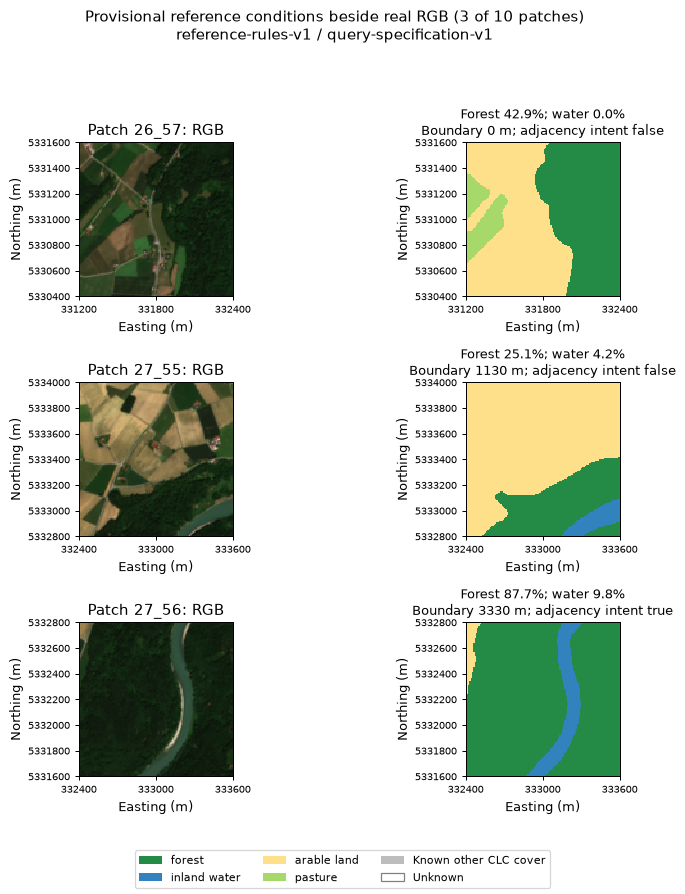

,patch,forest_fraction,water_fraction,boundary_m,adjacency_reference
0,26_57,0.428542,0.000000,0.0,false
1,27_55,0.250903,0.042431,1130.0,false
2,27_56,0.877431,0.098264,3330.0,true


In [5]:
class_names = list(rules["classes"])
cmap = ListedColormap([COLORS[name] for name in class_names] + ["#bdbdbd", "#ffffff"])
norm = BoundaryNorm(np.arange(7) - .5, 6)
fig, axes = plt.subplots(3, 2, figsize=(9, 10), dpi=90)
example_rows = []
for row, index in enumerate(EXAMPLE_INDICES):
    patch_id = patch_ids[index]
    summary = summaries[patch_id]
    files = patch_files(patch_id, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = inspect_patch(files)["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes[row, 0].imshow(load_rgb(files, upper=DISPLAY_UPPER_DN),
                        extent=extent, interpolation="nearest")
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for color_index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = color_index
    display_map[summary["unknown_mask"]] = 5
    axes[row, 1].imshow(display_map, cmap=cmap, norm=norm,
                        extent=extent, interpolation="nearest")
    suffix = "_".join(patch_id.rsplit("_", 2)[1:])
    forest = summary["classes"]["forest"]["fraction_lower"]
    water = summary["classes"]["inland_water"]["fraction_lower"]
    boundary = summary["pairs"][("forest", "inland_water")]["boundary_lower_m"]
    state = decisions.loc[patch_id, "adjacent-forest-water"]
    axes[row, 0].set_title(f"Patch {suffix}: RGB")
    axes[row, 1].set_title(f"Forest {forest:.1%}; water {water:.1%}\n"
                          f"Boundary {boundary:.0f} m; adjacency intent {state}", fontsize=10)
    for ax in axes[row]:
        ax.set(xlabel="Easting (m)", ylabel="Northing (m)")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.tick_params(labelsize=8)
        ax.set_xticks(np.linspace(left, right, 3))
    example_rows.append({"patch": suffix, "forest_fraction": forest,
                         "water_fraction": water, "boundary_m": boundary,
                         "adjacency_reference": state})
fig.legend(handles=[Patch(facecolor=COLORS[name], label=name.replace("_", " "))
                    for name in class_names] +
                   [Patch(facecolor="#bdbdbd", label="Known other CLC cover"),
                    Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown")],
           loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Provisional reference conditions beside real RGB (3 of 10 patches)\n"
             "reference-rules-v1 / query-specification-v1", fontsize=12)
fig.tight_layout(rect=(0, .07, 1, .94))
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/reference-pilot-v1-examples.png", dpi=110)
plt.show()
pd.DataFrame(example_rows)

Patch 26_57 has no mapped inland water, so the forest/water intent is false.
Patch 27_55 has mapped water and 1,130 m of forest/water boundary, but water covers
only about 4.24%; its 5% presence condition fails. Patch 27_56 has about 9.83% water
and 3,330 m of mapped boundary, satisfying both presence and contact requirements.
These outcomes follow our specified thresholds, not a claim that RGB alone
proves those quantities. Visual inspection supports broad spatial correspondence: fields and woodland
in the first two scenes, and a river corridor through woodland in the third.
Smaller field boundaries and the riverbank/road corridor are more detailed in RGB
than in the map. The threshold-driven negative for patch 27_55 remains negative
even though water is visibly plausible. No visual inspection independently
verifies exact forest class membership, cover percentages or every boundary.

## 6. Which geographic evidence can we actually separate?

Country and tile names describe the source population, but do not establish
cross-tile overlap or distances. We use the verified native raster footprints,
transform densified bounds to the European metric CRS EPSG:3035, and group any
footprints whose envelope distance is **at most 2,000 m**. Connected components
include transitive chains and repeated acquisitions regardless of date. Envelopes
are conservative; grouping may retain more images together than precise polygons.
The buffer exceeds a 1,200-m patch edge and reduces immediate-neighborhood leakage;
it is not a demonstrated statistical independence distance.

All already inspected/encoded pilot IDs anchor their whole component in
**development**. Other verified components would be assigned by a fixed SHA-256
hash and 0.5 test fraction, without label-based balancing. Unverified selections
remain unassigned. Country, provider split, date or a random patch-ID split cannot
replace this spatial check.

available_images            10
countries                    1
MGRS_tiles                   1
acquisition_dates            1
identical_native_pairs       0
overlapping_native_pairs     0
spatial_components           1
development_images          10
held_out_test_images         0
dtype: int64

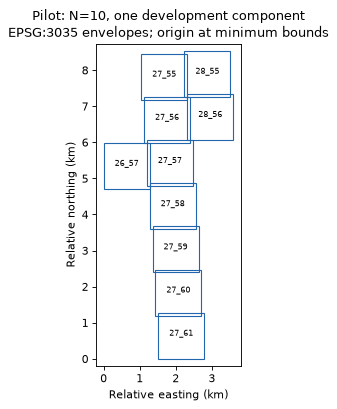

In [6]:
footprints = verified_footprints(patch_ids, RAW)
assignment = spatial_split(footprints, patch_ids, DESIGN["spatial"])
assert assignment.split.eq("development").all()
assert assignment.groupby("group_id").split.nunique().eq(1).all()
available_catalog = catalog.set_index("patch_id").loc[patch_ids]
# Native overlap audit is specific to this available single-CRS pilot.
assert footprints.native_crs.nunique() == 1
native_boxes = footprints.native_bounds.tolist()
identical_pairs = sum(a == b for a, b in combinations(native_boxes, 2))
overlapping_pairs = sum(max(a[0], b[0]) < min(a[2], b[2]) and
                        max(a[1], b[1]) < min(a[3], b[3])
                        for a, b in combinations(native_boxes, 2))
geography = pd.Series({"available_images": len(patch_ids),
                       "countries": available_catalog.country.nunique(),
                       "MGRS_tiles": footprints.tile.nunique(),
                       "acquisition_dates": footprints.date.nunique(),
                       "identical_native_pairs": identical_pairs,
                       "overlapping_native_pairs": overlapping_pairs,
                       "spatial_components": assignment.group_id.nunique(),
                       "development_images": int(assignment.split.eq("development").sum()),
                       "held_out_test_images": int(assignment.split.eq("test").sum())})
display(geography)
fig_geo, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
origin_x, origin_y = footprints.left.min(), footprints.bottom.min()
for pid, row in footprints.iterrows():
    ax.add_patch(plt.Rectangle(((row.left-origin_x)/1000, (row.bottom-origin_y)/1000),
                              (row.right-row.left)/1000, (row.top-row.bottom)/1000,
                              fill=False, edgecolor="#2166ac"))
    ax.text(((row.left+row.right)/2-origin_x)/1000,
            ((row.bottom+row.top)/2-origin_y)/1000,
            "_".join(pid.split("_")[-2:]), ha="center", fontsize=7)
ax.set_xlim(-.2, (footprints.right.max()-origin_x)/1000+.2)
ax.set_ylim(-.2, (footprints.top.max()-origin_y)/1000+.2)
ax.set_aspect("equal")
ax.set_xlabel("Relative easting (km)")
ax.set_ylabel("Relative northing (km)")
ax.set_title("Pilot: N=10, one development component\nEPSG:3035 envelopes; origin at minimum bounds")
plt.show()

All ten verified images lie in one connected component, one Austria tile and one
acquisition date, with zero identical native footprints or positive-area
native overlaps. Immediate neighbors still share landscape context. Moving any of these images to a final test set would split the
same development landscape across stages. The geographic diagram displays
projected bounding envelopes, not a more accurate land-cover map.

### 6.1 How do intent families and relation controls change the counts?

Families summarize **patch × intent decisions**, not independent images or
paraphrases. Every intent uses all ten main candidates. The controls below are
separate, explicitly filtered additional experiments: both class-presence
conditions must be true. Missing classes are not false spatial relations.
Unknown presence is reported outside eligibility; unknown relation remains
inside an eligible control. Unknown source causes are counted separately because
unknown pixels do not always make an intent undecidable.

In [7]:
intent_coverage, family_coverage, relation_coverage, control_ids = coverage_tables(
    decisions, queries, assignment.group_id)
display(intent_coverage)
display(family_coverage.assign(countries=geography["countries"],
                               spatial_components=geography["spatial_components"]))
display(relation_coverage)
candidate = load_benchmark_record(CANDIDATE_PATH, ROOT, require_frozen=False)
unknown_sources = pd.DataFrame(candidate["unknown_pixel_sources"])
display(unknown_sources[["missing_map", "masked_nodata_pixels",
                         "configured_unknown_pixels", "unexpected_code_pixels"]].sum()
        .rename("available-source totals"))

,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
intent_id,,,,,,,,,,
single-forest,forest-water,10,0,0,1.0,1,1,0,0,0
single-inland-water,forest-water,6,4,0,1.0,1,1,1,0,0
single-arable-land,arable-pasture,3,7,0,1.0,1,1,1,0,0
single-pasture,arable-pasture,5,5,0,1.0,1,1,1,0,0
both-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
adjacent-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
both-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images,countries,spatial_components
family_id,,,,,,,,
forest-water,28,12,0,40,1.0,10,1,1
arable-pasture,12,28,0,40,1.0,10,1,1


,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
intent_id,,,,,,,,,,,
adjacent-forest-water,forest-water,6,4,0,6,0,0,1.0,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,2,0,0,1.0,1,0,0


missing_map                  0
masked_nodata_pixels         0
configured_unknown_pixels    0
unexpected_code_pixels       0
Name: available-source totals, dtype: int64

The forest/water family has 28 positive and 12 negative patch-intent decisions;
arable/pasture has 12 and 28. Each family still sees only **ten unique images** in
one geographic component. All source masks/configured unknown codes/unrecognized
codes count zero here; all intent judgments are known. Controlled tests exercise
unknown source causes and ambiguous states, rather than inventing them in this
complete-map pilot. The six forest/water and two arable/pasture control candidates
have zero false relations. After removing the largest positive component,
**zero positives remain for every intent**.

## 7. Which reference-based requirements are necessary before freeze?

The versioned design requires at least 20 main candidates, ten positives and ten
negatives per fixed intent, three spatial components, and ten positives after
removing the largest positive component. Ten positives prevent a structural P@10
ceiling below one; negatives and N>10 prevent an all-positive or prevalence-only
task. Cluster removal requires dispersed evidence, not a power guarantee.

Each both-present relation control requires ten true and ten false relations,
three components, and five true/five false cases outside their respective largest
components. A presence-negative image cannot substitute for a relation-negative.
All judgments must be known for the complete main metric comparison, matching the
existing conservative metric contract. Unknown candidates are retained in rankings,
with main metrics undefined and separately named judged-only diagnostics; no
query-dependent reference filtering repairs the main collection.

These criteria were specified from development/reference limitations before any
new test reference inspection and without model scores. The existing 5%/60-m
semantics and 24 texts remain unchanged and provisional. No final test, semantic
retuning or model evaluation occurs here.

In [8]:
development_failures = freeze_blockers(intent_coverage, relation_coverage,
                                     DESIGN["coverage"], 0, queries)
display(pd.DataFrame({"development_gate_failure": development_failures}))
print("These failures describe development feasibility; there is no held-out test coverage yet.")

,development_gate_failure
0,single-forest: candidate count 10 < 20
1,single-forest: negatives 0 < 10
2,single-forest: positive dispersion 0 < 10
3,single-forest: spatial groups 1 < 3
4,single-inland-water: candidate count 10 < 20
5,single-inland-water: positives 6 < 10
6,single-inland-water: negatives 4 < 10
7,single-inland-water: positive dispersion 0 < 10
8,single-inland-water: spatial groups 1 < 3
9,single-arable-land: candidate count 10 < 20


These failures describe development feasibility; there is no held-out test coverage yet.


## 8. Can a bounded expansion reach a spatially broader inventory?

The pinned official clean catalog contains 480,038 patches across ten countries
and 54 MGRS tiles; its quality exclusions belong to the source population. The
predeclared rule selects **25 per country, 250 total**, spreading quotas across
SHA-256-ordered tiles and patches. The entire previously developed tile `33UUP`
is excluded. No land-cover label, caption or model result is read by sampling.
Equal-country quotas are deliberate enrichment, not population-proportional
sampling. Actual native geometry is still required before assigning splits.

The acquisition plan permits batches of 25 and a 64-MiB additional raster cap.
We do not replace inaccessible IDs with convenient early members, download full
archives, or grow indefinitely. The table below is an acquisition plan,
**not 250 downloaded/validated images**.

In [9]:
planned = select_catalog(catalog, DESIGN["selection"])
pd.testing.assert_frame_equal(planned, pd.read_csv(ROOT / "manifests/coverage-selection-v1.csv"))
display(planned.groupby("country").agg(planned_images=("patch_id", "size"),
                                       MGRS_tiles=("tile", "nunique")))
print(f"Selected {len(planned)} IDs across {planned.tile.nunique()} distinct tiles.")
access = json.loads((ROOT / "manifests/coverage-access-v1.json").read_text())
display(pd.DataFrame(access["inventory"]))
display(pd.DataFrame(access["tail_probes"])[["name", "size_bytes", "seekable_zstd_footer_present"]])
display(pd.Series(candidate["access"], name="verified access assessment"))

,planned_images,MGRS_tiles
country,,
Austria,25,7
Belgium,25,3
Finland,25,21
Ireland,25,5
Kosovo,25,1
Lithuania,25,7
Luxembourg,25,1
Portugal,25,3
Serbia,25,6


Selected 250 IDs across 53 distinct tiles.


,name,size_bytes
0,BigEarthNet-S1.tar.zst,54439153171
1,metadata.parquet,3616349
2,metadata_for_patches_with_snow_cloud_or_shadow...,710162
3,Reference_Maps.tar.zst,282391301
4,BigEarthNet-S2.tar.zst,63251710377


,name,size_bytes,seekable_zstd_footer_present
0,s2-tail-1024.bin,1024,False
1,maps-tail-1024.bin,1024,False


planned_count                       250
planned_tiles                        53
verified_new_patches                  0
test_count                            0
additional_archive_bytes           2048
selected_ids_in_cached_prefixes       0
Name: verified access assessment, dtype: int64

The official inventory lists monolithic S2/map archives, without a patch-member
index. The first compressed frames declare 102,406,983,680 and 1,534,300,160
uncompressed bytes. Enforced HTTP-range probes fetched **only 1,024 bytes per
archive** at the end; neither has the mandatory seekable-zstd footer. Re-scanning
existing finite prefixes reaches **zero** of the selected IDs. The official
compression recipe uses ordinary zstd, not a supplied seek table. This establishes
a limitation of the verified route, not proof that no future subset service can
exist. Sources and probe digests are in the versioned access record.

No new image/map patch was acquired. The 250 planned IDs have unverified images,
reference evidence and native geometry. They remain **unassigned**, rather than
being labeled irrelevant or advertised as held-out test data. Fetching more early
neighbors would not fulfill the predeclared geographically broader rule. The
bounded acquisition therefore stops instead of forcing a freeze.

## 9. What is specified, and what is still blocked?

`benchmark-candidate-v1` records the exact source/specification/code/input hashes,
verified geometry and development grouping, unfiltered development candidates,
separate relation controls, reference states, model/preprocessing specification
and the proposed evaluation design. It is **blocked-not-frozen**, with no test
candidates. The default evaluation loader refuses this status. Integrity checks
include the actual catalog and forty available source TIFFs, not merely filenames.

For work package 5, the design specifies equal arithmetic weighting across
formulations within each intent and equal weighting across fixed intents. No
undefined value is silently skipped. Controls remain separate. The paired
bootstrap will resample complete direct intent families with both models together,
10,000 draws, PCG64 seed 20261012, sum of sampled intent differences divided by
sampled intent count, and percentile 95% intervals. With only two families these
are conditional robustness diagnostics, not broad uncertainty claims. Top-10
paraphrase Jaccard and quality ranges are separate diagnostics. Later error
inspection is predeclared: formulation p1 of each intent, ranks 1/5/10 for both
models, with three-state error categories and separate manual reference-conflict
annotations. This package does not implement the statistics pipeline.

A valid freeze additionally needs bounded access to the selected raster inputs,
verified native coordinates, broader development plausibility checks, and adequate
held-out main/control reference coverage. No queries or thresholds will be retuned
against final model results. Changes after a future freeze need a new version and
reason; test-motivated changes are exploratory.

In [10]:
display(pd.Series({"record_version": candidate["version"], "status": candidate["status"],
                   "content_sha256": candidate["content_sha256"],
                   "held_out_images": len(candidate["main_candidates"]["test"])}))
display(pd.DataFrame({"freeze_blocker": candidate["blockers"]}))
try:
    load_benchmark_record(CANDIDATE_PATH, ROOT)
except ValueError as error:
    print("Expected evaluation gate:", error)
else:
    raise AssertionError("A blocked candidate must not be accepted as frozen.")

record_version                                benchmark-candidate-v1
status                                            blocked-not-frozen
content_sha256     977d09d62518e53d25b6904f93fb10c022410d2bd77407...
held_out_images                                                    0
dtype: object

,freeze_blocker
0,250 selected patches lack verified RGB/map access
1,No verified spatially held-out test candidate ...
2,Broader development reference/preprocessing pl...
3,Native coordinates for the selected inventory ...


Expected evaluation gate: Benchmark is blocked, not frozen; final evaluation is prohibited


## 10. Saved outputs, limits and next stage

The following outputs are provisional development artifacts. Their provenance
identifies exact source/specification bytes; they are not a benchmark freeze.
The reference matrix is independent of paraphrase count and model ranking.
No source captions or answers contribute to these calculated conditions.

In [11]:
output = ROOT / "outputs"
decisions.to_csv(output / "reference-decisions-v1.csv")
coverage.to_csv(output / "reference-coverage-v1.csv")
provenance = {
    "status": "provisional development artifact; not a final evaluation freeze",
    "reference_version": rules["version"], "query_version": queries["version"],
    "inputs_sha256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                      for path in [MANIFEST_PATH, RULES_PATH, QUERIES_PATH]},
    "decisions_sha256": hashlib.sha256((output / "reference-decisions-v1.csv").read_bytes()).hexdigest(),
    "patch_ids": patch_ids, "intent_ids": decisions.columns.tolist(),
}
(output / "reference-provenance-v1.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved provisional decisions, coverage, provenance and example figure under outputs/.")
coverage_output = ROOT / "outputs/coverage-v1"
coverage_output.mkdir(parents=True, exist_ok=True)
for name, table in [("intent", intent_coverage), ("family", family_coverage),
                    ("relations", relation_coverage), ("spatial", footprints.join(assignment))]:
    table.to_csv(coverage_output / f"{name}.csv")
geo_path = coverage_output / "spatial_components.png"
fig_geo.savefig(geo_path, dpi=130)
(coverage_output / "figure-provenance.json").write_text(json.dumps({
    "version": "coverage-v1", "candidate_content_sha256": candidate["content_sha256"],
    "figure_sha256": file_digest(geo_path), "candidate_sha256": file_digest(CANDIDATE_PATH)
}, indent=2) + "\n")
print("Saved geographic figure/coverage; versioned candidate remains explicitly not frozen.")

Saved provisional decisions, coverage, provenance and example figure under outputs/.
Saved geographic figure/coverage; versioned candidate remains explicitly not frozen.


Reusable reference calculation, deterministic selection, spatial grouping,
coverage/control construction and integrity checking live in `src`. Small tables
and the two explanatory figures remain in this existing notebook. Real integration
checks verify catalog selection, native footprints, the development-only component
and refusal of the blocked candidate. Fresh-kernel execution and visual inspection
verify the actual available RGB/map examples and geographic display.

The bounded-access blocker prevents a defensible final freeze. The next action is
to establish a checksum-identified, indexed official subset route for the selected
IDs (or provide a corresponding local subset with verifiable provenance), then
validate development plausibility and held-out coverage under a new candidate
version. Work package 5's final evaluation prerequisites remain unmet. No new
retrieval results, test-driven selection or statistical claims were produced.

## 11. Continuation: what evidence now resolves each blocker?

The previous sections establish the original blocked candidate. This continuation
preserves that record and all sampling/coverage/semantic rules. It distinguishes
planned inventory, files present, actually loaded/technically validated pairs and
independent scientific reference truth. No model weights, embeddings or rankings
are loaded. The next three distinct IDs after the original ten in the same pinned
400-row text snapshot were specified **before checking accessibility**. This small
supplemental development batch is not a replacement for any of the 250 planned IDs.

| Prerequisite | Cause | Required evidence |
|---|---|---|
| Broader planned input access | Monolithic ordinary-zstd official archives; current prefixes do not reach the selected IDs | Indexed official subset or provenance-verified local RGB/map files, initially the first 25 planned IDs |
| Native held-out geometry | Catalog country/tile labels are not coordinate evidence | Loaded aligned rasters with actual CRS/affine extents, complete spatial components and prior-development anchors |
| Reference suitability | 10-m storage inherits generalized CLC semantics; previous examples cannot establish fine-boundary truth | Explicitly scoped map-agreement claim or independently validated relation reference; broader development evidence |
| Main/control coverage | No forest negatives or both-present false relations; one component | All fixed minimum coverage/dispersion gates on a verified held-out collection |

### 11.1 Does the official cache contain a genuine small batch?

The same verified 2-MiB S2 and 256-KiB map prefixes contain all twelve required
files for the predefined three additional images. Exact complete member names,
lengths and SHA-256 digests are pinned in `development-validation-v2`. Canonical
acquisition and reference functions are reused. Technical validation additionally
checks text/catalog pairing, native raster centers against original latitude/
longitude to 1e-8 degree, identical RGB/map geometry, NoData and model RGB input
conversion. It does not infer thematic truth from technical alignment.

In [12]:
current = load_benchmark_record(CURRENT_CANDIDATE, ROOT, require_frozen=False)
source_checks = validate_development_sources(VALIDATION_MANIFEST, CACHE, RAW, DISPLAY_UPPER_DN)
v2_summaries, v2_decisions = evaluate_pilot(VALIDATION_MANIFEST, CACHE, RAW, rules, queries)
v2_ids = v2_decisions.index.tolist()
assert len(source_checks) == 13 and source_checks.index.tolist() == v2_ids
assert current["main_candidates"]["development"] == v2_ids
scope_table = pd.DataFrame([
    {"collection": "Planned broader inventory", "planned": 250,
     "complete_files_present": current["access"]["planned_complete_files_present"],
     "loaded_and_technically_validated": 0, "development": 0, "test": 0,
     "fine_visual_boundary_truth_validated": 0},
    {"collection": "Available development (10 previous + 3 additional)", "planned": 13,
     "complete_files_present": 13, "loaded_and_technically_validated": 13,
     "development": 13, "test": 0, "fine_visual_boundary_truth_validated": 0}])
display(scope_table)
display(source_checks.iloc[NEW_EXAMPLE_POSITIONS][[
    "annotation_id", "catalog_status", "crs", "height", "width", "pixel_width_m",
    "rgb_nodata", "map_nodata", "rgb_masked_values", "map_masked_pixels",
    "identical_rgb_map_grid", "text_center_error_deg"]])
print("New archive bytes in this continuation: 0; extracted/validated source files: 52.")

,collection,planned,complete_files_present,loaded_and_technically_validated,development,test,fine_visual_boundary_truth_validated
0,Planned broader inventory,250,0,0,0,0,0
1,Available development (10 previous + 3 additio...,13,13,13,13,0,0


,annotation_id,catalog_status,crs,height,width,pixel_width_m,rgb_nodata,map_nodata,rgb_masked_values,map_masked_pixels,identical_rgb_map_grid,text_center_error_deg
patch_id,,,,,,,,,,,,
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_57,265,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,0.000000e+00
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_58,283,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,0.000000e+00
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_59,309,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,7.105427e-15


New archive bytes in this continuation: 0; extracted/validated source files: 52.


### 11.2 What does the reference's underlying scale support?

The source maps store raw CLC codes at 10 m. The underlying CLC2018 status
inventory has a **25-ha minimum mapping unit and 100-m minimum linear width**,
as documented by [Copernicus](https://www.copernicus.eu/en/access-data/copernicus-services-catalogue/corine-land-cover-2018-vector-europe-6-yearly-version).
This is generalized source information, not a newly surveyed 10-m reference.
A 144-ha patch's 5% threshold is 7.2 ha. The MMU describes original polygons;
clipping a larger polygon can legitimately leave less than 25 ha within a patch.
Likewise minimum feature width is not summed shared-boundary length. These
numbers do **not** logically invalidate the existing computations or provide a
reason to replace 5%/60 m automatically.

The calculations are reproducible measures of the stored map. They do not
establish exact visible cover fractions or a reliably surveyed 60-m contact.
Small linear structures, generalized boundaries and acquisition/year differences
remain uncertain. Proposal: retain a clearly scoped map-agreement interpretation,
or acquire independent boundary evidence before making visual-relation claims.
This remains an open scientific decision, not a silent change of queries or rules.
The following examples only inspect broad RGB/map plausibility.

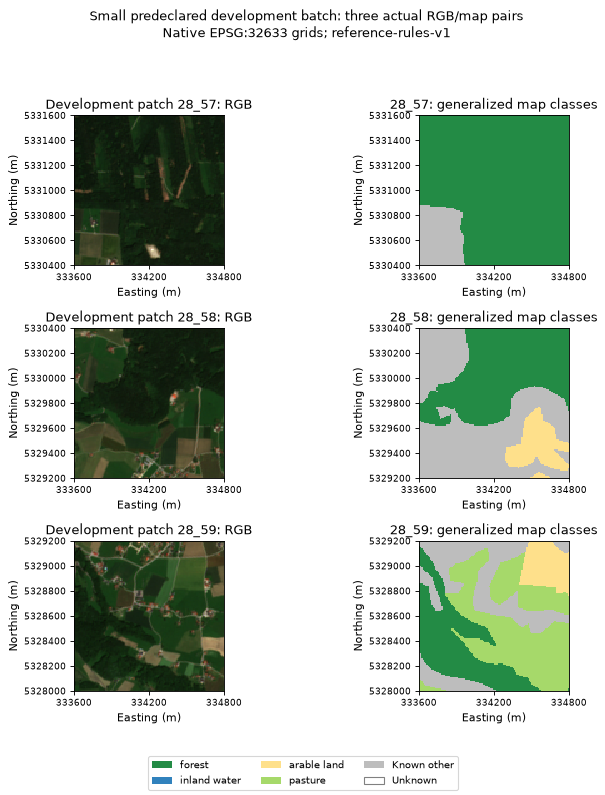

,patch,forest_fraction,inland_water_fraction,arable_land_fraction,pasture_fraction
0,28_57,0.8869,0.0,0.0000,0.0000
1,28_58,0.4206,0.0,0.1006,0.0000
2,28_59,0.2499,0.0,0.0885,0.3975


In [13]:
new_ids = [v2_ids[index] for index in NEW_EXAMPLE_POSITIONS]
fig_v2, axes_v2 = plt.subplots(3, 2, figsize=(9, 10), dpi=80)
new_evidence = []
for row, pid in enumerate(new_ids):
    summary = v2_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = inspect_patch(files)["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes_v2[row, 0].imshow(load_rgb(files, upper=DISPLAY_UPPER_DN), extent=extent,
                           interpolation="nearest")
    aggregated_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        aggregated_map[summary["class_masks"][name]] = index
    aggregated_map[summary["unknown_mask"]] = 5
    axes_v2[row, 1].imshow(aggregated_map, extent=extent, cmap=cmap, norm=norm,
                           interpolation="nearest")
    suffix = "_".join(pid.split("_")[-2:])
    axes_v2[row, 0].set_title(f"Development patch {suffix}: RGB")
    axes_v2[row, 1].set_title(f"{suffix}: generalized map classes")
    for ax in axes_v2[row]:
        ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.set_xticks(np.linspace(left, right, 3)); ax.tick_params(labelsize=8)
    new_evidence.append({"patch": suffix, **{
        name + "_fraction": summary["classes"][name]["fraction_lower"]
        for name in class_names}})
fig_v2.legend(handles=[Patch(facecolor=COLORS[name], label=name.replace("_", " "))
                      for name in class_names] +
              [Patch(facecolor="#bdbdbd", label="Known other"),
               Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown")],
              loc="lower center", ncol=3, fontsize=9)
fig_v2.suptitle("Small predeclared development batch: three actual RGB/map pairs\n"
               "Native EPSG:32633 grids; reference-rules-v1", fontsize=12)
fig_v2.tight_layout(rect=(0, .07, 1, .94))
v2_output = ROOT / "outputs/development-validation-v2"
v2_output.mkdir(parents=True, exist_ok=True)
fig_v2.savefig(v2_output / "development-examples.png", dpi=110)
plt.show()
display(pd.DataFrame(new_evidence).round(4))

Visual inspection shows broadly corresponding woodland and field patterns. Patch
28_57 has small bright clearings/linear structures in RGB that the generalized
map does not resolve separately. Patch 28_58 mixes fields and woodland; gray is
known other CLC cover, not missing evidence. Patch 28_59 illustrates generalized
field boundaries and mapped pasture/arable distinctions that RGB color alone
cannot independently verify. These observations support coarse alignment and
expose reference limitations; they do not validate exact cover percentages,
contact lengths or all thematic labels.

### 11.3 Did new development evidence establish a test collection?

Recompute spatial components using actual native extents and the unchanged
2-km envelope rule. All explored images anchor their components in development.
Coverage uses full three-state references, not captions or model results;
relation controls require both true presences and retain unknown relation states.
We apply the existing gates rather than lowering them to obtain a passing status.

In [14]:
v2_footprints = verified_footprints(v2_ids, RAW)
v2_split = spatial_split(v2_footprints, v2_ids, DESIGN["spatial"])
v2_intent, v2_family, v2_relation, v2_controls = coverage_tables(
    v2_decisions, queries, v2_split.group_id)
display(v2_intent[["true", "false", "unknown", "judged_fraction",
                   "spatial_groups", "positive_outside_largest_group"]])
display(v2_family)
display(v2_relation[["both_present", "true", "false", "unknown", "missing_class"]])
display(pd.Series({"loaded_development": len(v2_ids),
                   "components": v2_split.group_id.nunique(),
                   "countries": source_checks.country.nunique(),
                   "test_images": int(v2_split.split.eq("test").sum())}))
assert v2_split.split.eq("development").all()
assert v2_controls == current["relation_controls"]["development"]
display(pd.DataFrame({"unchanged_development_gate_failure": current["development_gate_failures"]}))

,true,false,unknown,judged_fraction,spatial_groups,positive_outside_largest_group
intent_id,,,,,,
single-forest,13,0,0,1.0,1,0
single-inland-water,6,7,0,1.0,1,0
single-arable-land,5,8,0,1.0,1,0
single-pasture,6,7,0,1.0,1,0
both-forest-water,6,7,0,1.0,1,0
adjacent-forest-water,6,7,0,1.0,1,0
both-arable-pasture,3,10,0,1.0,1,0
adjacent-arable-pasture,3,10,0,1.0,1,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images
family_id,,,,,,
forest-water,31,21,0,52,1.0,13
arable-pasture,17,35,0,52,1.0,13


,both_present,true,false,unknown,missing_class
intent_id,,,,,
adjacent-forest-water,6,6,0,0,7
adjacent-arable-pasture,3,3,0,0,10


loaded_development    13
components             1
countries              1
test_images            0
dtype: int64

,unchanged_development_gate_failure
0,single-forest: candidate count 13 < 20
1,single-forest: negatives 0 < 10
2,single-forest: positive dispersion 0 < 10
3,single-forest: spatial groups 1 < 3
4,single-inland-water: candidate count 13 < 20
5,single-inland-water: positives 6 < 10
6,single-inland-water: negatives 7 < 10
7,single-inland-water: positive dispersion 0 < 10
8,single-inland-water: spatial groups 1 < 3
9,single-arable-land: candidate count 13 < 20


The enlarged development collection still has one component and no forest
negative. Forest/water controls remain six true / zero false; arable/pasture now
has three true / zero false. The three real additions increase technical evidence,
but do not fix geography or hard-relation coverage. No planned image is acquired
or assigned to test; all 250 planned IDs remain unassigned. No test reference,
embedding or ranking has been generated.

### 11.4 Freeze decision and smallest next action

`benchmark-candidate-v2` explicitly records this revision and remains
**blocked-not-frozen**. Both original and revised candidates are integrity checked;
the default loader refuses both for final evaluation. A controlled positive
protocol fixture tests successful validation when all structural/coverage
requirements genuinely match; it is not a fabricated research dataset.

The official complete S2/map archives total 63,534,101,678 bytes. This task does
not authorize downloading them. The smallest next action is to provide an
indexed official endpoint or a provenance-verified local subset for the **first
25 planned IDs**, each with B04/B03/B02 and its original reference TIFF (100 files).
Their byte sizes and checksums must be checked before further batches. No new
alternative dataset or relaxed freeze criteria are proposed as a workaround.
Broader development geometry, thematic plausibility and held-out coverage must
still pass before a real freeze. Work package 5 remains gated.

In [15]:
for version in [CANDIDATE_PATH, CURRENT_CANDIDATE]:
    try:
        load_benchmark_record(version, ROOT)
    except ValueError as error:
        print(version.name, "rejected as expected:", error)
    else:
        raise AssertionError("Incomplete candidate unexpectedly accepted")
(v2_output / "figure-provenance.json").write_text(json.dumps({
    "candidate_version": current["version"], "candidate_sha256": file_digest(CURRENT_CANDIDATE),
    "selected_development_ids": new_ids,
    "figure_sha256": file_digest(v2_output / "development-examples.png")
}, indent=2) + "\n")
print("Saved current development diagnostics and figure; no freeze or final evaluation.")

benchmark-candidate-v1.json rejected as expected: Benchmark is blocked, not frozen; final evaluation is prohibited
benchmark-candidate-v2.json rejected as expected: Benchmark is blocked, not frozen; final evaluation is prohibited
Saved current development diagnostics and figure; no freeze or final evaluation.
